# K-means vs DBSCAN – Model Comparison
Compares the two clustering solutions produced in `01_KMeans_Clustering.ipynb` and `02_DBSCAN_Clustering.ipynb` on the **same 1,097 bricks and the same 7 scaled features**.

> Run notebooks 01 and 02 first – this notebook reads their outputs from the `artifacts/` folder.

Because the two algorithms have different philosophies (K-means partitions *every* brick; DBSCAN labels low-density bricks as *noise*), a fair comparison needs more than one table: we compare headline metrics, then re-score K-means on DBSCAN's clustered subset, then measure how much the two solutions agree.

## 1. Load artefacts

In [1]:
%matplotlib inline
import warnings, json, os
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, adjusted_mutual_info_score, normalized_mutual_info_score)
sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 90
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

Z = pd.read_csv("artifacts/brick_features_scaled.csv", index_col=0)
KM = pd.read_csv("artifacts/kmeans_labels.csv", index_col=0); DB = pd.read_csv("artifacts/dbscan_labels.csv", index_col=0)
km_m = json.load(open("artifacts/kmeans_metrics.json")); db_m = json.load(open("artifacts/dbscan_metrics.json"))
assert (Z.index == KM.index).all() and (Z.index == DB.index).all()
D = KM[["State", "L12M", "P12M", "KMeans_Cluster", "KMeans_Segment"]].join(DB[["DBSCAN_Cluster", "DBSCAN_Segment", "Point_Type"]])
k_lab, d_lab = D["KMeans_Cluster"].values, D["DBSCAN_Cluster"].values
clustered = d_lab != -1
print(f"K-means: k={km_m['k']} | DBSCAN: eps={db_m['eps']}, min_samples={db_m['min_samples']} | bricks={len(D)}")

K-means: k=4 | DBSCAN: eps=1.45, min_samples=14 | bricks=1097


## 2. Headline metrics
All internal metrics are **recomputed here** from the saved labels. Three views are shown so that neither model is flattered:
1. **K-means (all bricks)** – its native view.
2. **DBSCAN (clustered bricks only)** – its native view (noise excluded).
3. **K-means on the same bricks DBSCAN kept** – like-for-like comparison.
4. **DBSCAN (noise as its own group)** – penalises DBSCAN for leaving bricks unassigned.

In [2]:
def scores(Zv, lab, name, extra=None):
    n_c = len(set(lab))
    r = {"View": name, "Bricks scored": len(lab), "Clusters": n_c,
         "Silhouette": silhouette_score(Zv, lab), "Davies-Bouldin (lower=better)": davies_bouldin_score(Zv, lab),
         "Calinski-Harabasz": calinski_harabasz_score(Zv, lab),
         "Largest cluster %": np.bincount(pd.factorize(lab)[0]).max() / len(lab),
         "Smallest cluster": int(np.bincount(pd.factorize(lab)[0]).min())}
    return r
rows = [scores(Z.values, k_lab, "K-means - all bricks"),
        scores(Z.values[clustered], d_lab[clustered], "DBSCAN - clustered bricks only"),
        scores(Z.values[clustered], k_lab[clustered], "K-means - same bricks as DBSCAN"),
        scores(Z.values, d_lab, "DBSCAN - noise as own group")]
tbl = pd.DataFrame(rows).set_index("View")
display(tbl.style.format({"Silhouette": "{:.3f}", "Davies-Bouldin (lower=better)": "{:.2f}", "Calinski-Harabasz": "{:.0f}", "Largest cluster %": "{:.1%}"}))

ops = pd.DataFrame({
    "K-means": {"Bricks assigned": 1.0, "Clusters found": km_m["k"], "Bootstrap stability (ARI)": km_m["bootstrap_ARI"], "Agreement with State (ARI)": km_m["ari_vs_state"]},
    "DBSCAN": {"Bricks assigned": db_m["coverage_pct"], "Clusters found": db_m["n_clusters"], "Bootstrap stability (ARI)": db_m["bootstrap_ARI"], "Agreement with State (ARI)": db_m["ari_vs_state"]}}).T
display(ops.style.format({"Bricks assigned": "{:.1%}", "Clusters found": "{:.0f}", "Bootstrap stability (ARI)": "{:.3f}", "Agreement with State (ARI)": "{:.3f}"}))

,Bricks scored,Clusters,Silhouette,Davies-Bouldin (lower=better),Calinski-Harabasz,Largest cluster %,Smallest cluster
View,,,,,,,
K-means - all bricks,1097,4,0.169,1.57,251,43.5%,16
DBSCAN - clustered bricks only,936,2,0.337,0.94,81,97.0%,28
K-means - same bricks as DBSCAN,936,3,0.167,1.72,157,49.5%,44
DBSCAN - noise as own group,1097,3,0.250,2.52,147,82.8%,28


,Bricks assigned,Clusters found,Bootstrap stability (ARI),Agreement with State (ARI)
K-means,100.0%,4,0.800,0.003
DBSCAN,85.3%,2,0.911,0.003


> **Insight —** On internal metrics DBSCAN looks better – silhouette 0.337 vs 0.169, Davies-Bouldin 0.94 vs 1.57 – and still ahead when noise is penalised (0.250). Calinski-Harabasz favours K-means (251 vs 81). The DBSCAN scores are flattered by one cluster holding 97 % of clustered bricks; K-means on the same 936 bricks scores 0.167. DBSCAN is more stable (ARI 0.91 vs 0.80) but leaves 14.7 % of bricks unassigned. Neither relates to State (ARI 0.003).

## 3. Side-by-side picture
Same PCA projection, coloured by each model.

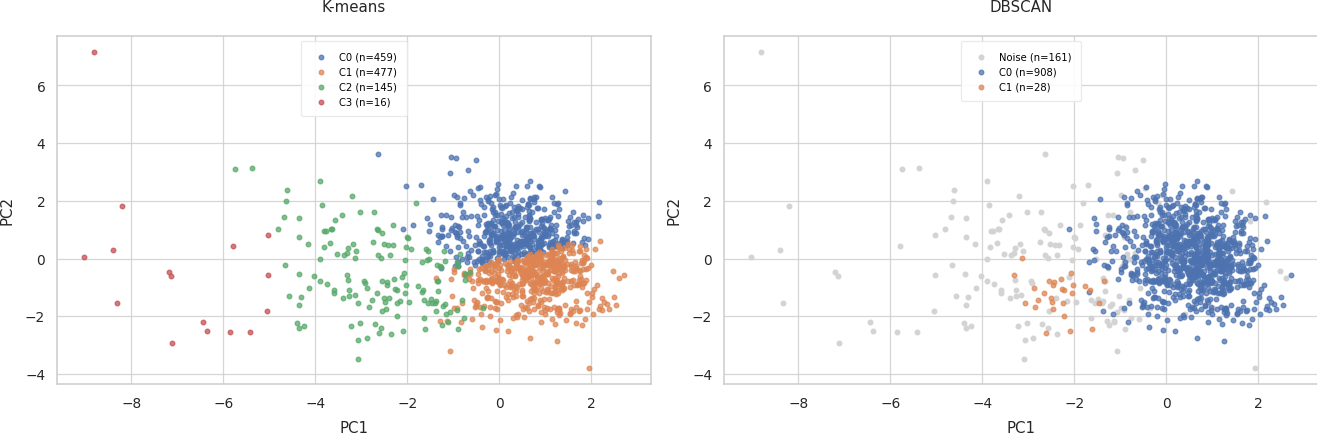

In [3]:
P = PCA(n_components=2, random_state=42).fit_transform(Z)
fig, ax = plt.subplots(1, 2, figsize=(15, 5.2))
for c in sorted(set(k_lab)): ax[0].scatter(P[k_lab == c, 0], P[k_lab == c, 1], s=14, alpha=.75, label=f"C{c} (n={(k_lab == c).sum()})")
ax[0].set_title("K-means"); ax[0].legend(fontsize=8)
ax[1].scatter(P[~clustered, 0], P[~clustered, 1], c="lightgrey", s=14, label=f"Noise (n={(~clustered).sum()})")
for c in sorted(set(d_lab) - {-1}): ax[1].scatter(P[d_lab == c, 0], P[d_lab == c, 1], s=14, alpha=.75, label=f"C{c} (n={(d_lab == c).sum()})")
ax[1].set_title("DBSCAN"); ax[1].legend(fontsize=8)
for a in ax: a.set_xlabel("PC1"); a.set_ylabel("PC2")
plt.tight_layout(); plt.show()

> **Insight —** K-means slices the main body in two along growth (C0 vs C1) and splits the left-hand tail into two clusters; DBSCAN keeps the body whole, picks one small pocket (28 bricks) and shades the periphery as noise.

## 4. How much do the two solutions agree?
Cross-tabulation plus agreement indices (ARI / AMI / NMI; 1 = identical partitions, 0 = chance).

DBSCAN label (-1=noise),-1,0,1
K-means cluster,,,
0,30,429,0
1,14,463,0
2,101,16,28
3,16,0,0


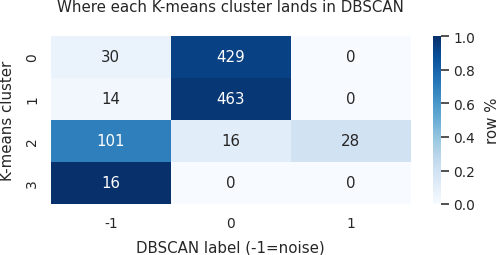

,Agreement
"ARI (all bricks, noise = own label)",0.260
AMI (all bricks),0.332
NMI (all bricks),0.335
ARI (DBSCAN-clustered bricks only),0.095


In [4]:
ct = pd.crosstab(D["KMeans_Cluster"].rename("K-means cluster"), D["DBSCAN_Cluster"].rename("DBSCAN label (-1=noise)"))
display(ct)
plt.figure(figsize=(6, 3.2)); sns.heatmap(ct.div(ct.sum(axis=1), axis=0), annot=ct, fmt="d", cmap="Blues", cbar_kws={"label": "row %"})
plt.title("Where each K-means cluster lands in DBSCAN"); plt.tight_layout(); plt.show()

agree = pd.Series({
    "ARI (all bricks, noise = own label)": adjusted_rand_score(k_lab, d_lab),
    "AMI (all bricks)": adjusted_mutual_info_score(k_lab, d_lab),
    "NMI (all bricks)": normalized_mutual_info_score(k_lab, d_lab),
    "ARI (DBSCAN-clustered bricks only)": adjusted_rand_score(k_lab[clustered], d_lab[clustered])})
display(agree.round(3).to_frame("Agreement"))

> **Insight —** Agreement is modest: ARI 0.26, AMI 0.33, NMI 0.34 on all bricks and only 0.10 ARI on bricks DBSCAN clustered. They agree on the **tail** (K-means C2 → 101 noise + all 28 of DBSCAN's Cluster 1; C3 → 16/16 noise) but disagree on the **interior**: DBSCAN puts K-means C0 and C1 (429 and 463 bricks) into one cluster – the growth-based split is invisible to a density method.

## 5. Do the two models find the same "problem" bricks?
K-means isolates its smallest cluster(s) of tiny, volatile bricks; DBSCAN calls low-density bricks noise. We check the overlap and profile both groups.

In [5]:
small_km = D["KMeans_Cluster"].isin(pd.Series(k_lab).value_counts().nsmallest(2).index)   # two smallest K-means clusters
noise = pd.Series(~clustered, index=D.index)
ov = pd.crosstab(small_km.rename("In 2 smallest K-means clusters"), noise.rename("DBSCAN noise"))
display(ov)
prec = (small_km & noise).sum() / noise.sum(); rec = (small_km & noise).sum() / small_km.sum()
print(f"Share of DBSCAN noise that sits in K-means' two smallest clusters: {prec:.1%} | Share of those K-means clusters flagged as noise: {rec:.1%}")

grp = pd.concat({"DBSCAN noise": D[noise], "K-means 2 smallest": D[small_km], "Both flag": D[noise & small_km], "Neither": D[~noise & ~small_km]})
cmp_ = grp.groupby(level=0).agg(Bricks=("L12M", "size"), Avg_L12M_units=("L12M", "mean"), Median_L12M=("L12M", "median"))
display(cmp_.round(0))
print("Where DBSCAN noise lands in K-means:"); print(D.loc[noise, "KMeans_Cluster"].value_counts().sort_index().to_string())

DBSCAN noise,False,True
In 2 smallest K-means clusters,,
False,892,44
True,44,117


Share of DBSCAN noise that sits in K-means' two smallest clusters: 72.7% | Share of those K-means clusters flagged as noise: 72.7%


,Bricks,Avg_L12M_units,Median_L12M
Both flag,117,90.0,89.0
DBSCAN noise,161,313.0,107.0
K-means 2 smallest,161,97.0,97.0
Neither,892,687.0,488.0


Where DBSCAN noise lands in K-means:
KMeans_Cluster
0     30
1     14
2    101
3     16


> **Insight —** 117 of DBSCAN's 161 noise bricks (72.7 %) sit in K-means' two smallest clusters, and 72.7 % of those 161 bricks are flagged as noise; the overlap averages only 90 units/year vs 687 for the rest. The other 44 noise bricks lie inside K-means' large clusters and include extreme-volume bricks (noise mean 313 vs median 107) – DBSCAN spots *unusual* bricks that K-means cannot, in both directions.

## 6. Scorecard & recommendation

In [6]:
score = pd.DataFrame([
 ["Segments actionable for sales / coverage planning", "K-means - 4 sized, differentiated segments (growth vs decline, 2 tails); DBSCAN - one segment holds 83% of bricks"],
 ["Internal cluster quality (silhouette / DB)", "DBSCAN - silhouette 0.34 vs 0.17, DB 0.94 vs 1.57 (flattered by one dominant cluster; Calinski-Harabasz favours K-means 251 vs 81)"],
 ["Coverage (bricks assigned to a segment)", "K-means - 100% of bricks assigned vs 85.3%"],
 ["Stability under resampling", "DBSCAN - bootstrap ARI 0.91 vs 0.80"],
 ["Sensitivity to hyper-parameters", "K-means - one parameter (k); DBSCAN 2-cluster result exists only at eps = 1.45"],
 ["Outlier / data-quality detection", "DBSCAN - 161 atypical bricks flagged natively, low and high volume"],
 ["Independence from geography (State)", "Tie - both independent of State (ARI 0.003)"]], columns=["Criterion", "Verdict"])
display(score.style.hide(axis="index").set_properties(**{"text-align": "left"}))

Criterion,Verdict
Segments actionable for sales / coverage planning,"K-means - 4 sized, differentiated segments (growth vs decline, 2 tails); DBSCAN - one segment holds 83% of bricks"
Internal cluster quality (silhouette / DB),"DBSCAN - silhouette 0.34 vs 0.17, DB 0.94 vs 1.57 (flattered by one dominant cluster; Calinski-Harabasz favours K-means 251 vs 81)"
Coverage (bricks assigned to a segment),K-means - 100% of bricks assigned vs 85.3%
Stability under resampling,DBSCAN - bootstrap ARI 0.91 vs 0.80
Sensitivity to hyper-parameters,K-means - one parameter (k); DBSCAN 2-cluster result exists only at eps = 1.45
Outlier / data-quality detection,"DBSCAN - 161 atypical bricks flagged natively, low and high volume"
Independence from geography (State),Tie - both independent of State (ARI 0.003)


> **Insight —** K-means wins on actionability, coverage and tuning simplicity; DBSCAN wins on stability at fixed parameters, headline silhouette and outlier detection.

## 7. Conclusions
**Recommendation: use K-means (k = 4) as the segmentation backbone and DBSCAN as an outlier overlay – not as alternatives.**

| | K-means (k = 4) | DBSCAN (eps 1.45, min_samples 14) |
|---|---|---|
| Output | 4 segments, every brick assigned | 2 clusters + 161 noise bricks (14.7 %) |
| Silhouette | 0.169 | 0.337 (0.250 noise as group) |
| Davies-Bouldin / CH | 1.57 / 251 | 0.94 / 81 |
| Stability (bootstrap ARI) | 0.80 | 0.91 |
| Biggest segment | 43.5 % of bricks | 82.8 % of bricks |
| Geography bias (ARI vs State) | 0.003 | 0.003 |

- **Why K-means for planning:** it splits the core into Growers (+2.7 %) and Decliners (−4.0 %), the actionable distinction in a flat market; DBSCAN sees one dense mass.
- **Why keep DBSCAN:** it reliably flags 161 atypical bricks (72.7 % of them are the tiny/volatile tail K-means also isolates; the rest include unusually large bricks) for review or exclusion.
- **Practical hybrid:** assign each brick its K-means segment and add a DBSCAN `Atypical` flag.
- **Caveats:** internal metrics are low for both (continuum-like data); DBSCAN is parameter-fragile; data is synthetic. Validate with business KPIs (e.g. incremental volume after targeting) before operational use.